#### <font color="skyblue"> Constraint optimization with real data </font> ####
        

$$\max_{\alpha,\beta >0} \ln L(\alpha,\beta)$$

where 
        $$L(\alpha,\beta)=\prod_{i=1}^n f_t(v_i |\alpha,\beta)F_T(u_i|\alpha,\beta)^{-1}$$

$$f_t(v|\alpha,\beta)=\alpha\beta v^{\beta-1}exp(-\alpha v^{\beta})$$
$$F_T(u|\alpha,\beta)=1-exp(-\alpha u^{\beta})$$

and $\{v_i\}$ and $\{u_i\}$ are the observed data points from the file UV.txt (http://web.ntpu.edu.tw/~ccw/statmath/UV.txt)

Note: 請留意概似函數中的 $f_t(v|\alpha,\beta)=\alpha\beta v^{\beta-1}exp(-\alpha v^{\beta})$ 是 Weibull distribution（韋伯分配） 的 PDF 函數。本題取材自一個存活分析的研究，關於左截切與右刪失資料（left-truncated and right-censored data）的適合度檢定。

<hr>

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

<font color="yellow">**Task 0**</font>: Derive the log-likelihood function $\ln L(\alpha, \beta)$

The following is the log-likelihood function for the given likelihood function and is derived by Copilot.

$$
\ln L(\alpha,\beta) = n\ln\alpha +n\ln\beta +(\beta-1)\sum_{i=1}^{n}\ln v_i -\alpha\sum_{i=1}^{n}v_i^\beta \\ -\sum_{i=1}^{n} \ln\!\left(1-e^{-\alpha u_i^\beta}\right)
$$

<font color=yellow>**Task 1**</font> : define the function $L(\alpha,\beta)$ and its log-likelihood function $\ln L(\alpha,\beta)$ in Python.

In [25]:
# define the log-likelihood function
def log_likelihood(alpha, beta, v, u):
    n = len(v)
    term1 = n * np.log(alpha)
    term2 = n * np.log(beta)
    term3 = (beta - 1) * np.sum(np.log(v))
    term4 = -alpha * np.sum(v ** beta)
    term5 = -np.sum(np.log(1 - np.exp(-alpha * u ** beta)))
    
    return term1 + term2 + term3 + term4 + term5

#define the negative log-likelihood function
def neg_log_likelihood(params, v, u):
    alpha, beta = params
    return -log_likelihood(alpha, beta, v, u)

<font color=yellow>**Task 2**</font> : Draw the contour plot of $\ln L(\alpha,\beta)$ for $\alpha$ and $\beta$ in suitable ranges that show the maximum.

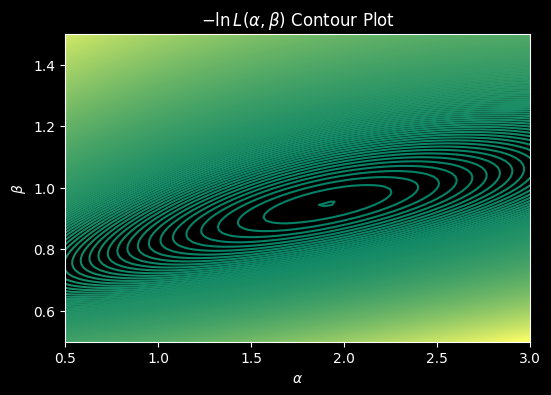

In [26]:
# draw the contour plot of the negative log-likelihood function

# load the data from data/UV.txt and skip the first row
data = np.loadtxt('data/UV.txt', skiprows=1)
u = data[:, 0]
v = data[:, 1]

# Create a grid of alpha and beta values
alpha_range = np.linspace(0.5, 3, 100)
beta_range = np.linspace(0.5, 1.5, 100)
alpha_grid, beta_grid = np.meshgrid(alpha_range, beta_range)

# Calculate the negative log-likelihood for each point in the grid
Z = np.zeros_like(alpha_grid)
for i in range(len(alpha_range)):
    for j in range(len(beta_range)):
        Z[j, i] = neg_log_likelihood((alpha_grid[j, i], beta_grid[j, i]), v, u)

# Create the contour plot
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(6, 4))
plt.contour(alpha_grid, beta_grid, Z, levels=300, cmap = plt.cm.summer)
plt.xlabel('$\\alpha$')
plt.ylabel('$\\beta$')
plt.title('$-\ln L(\\alpha, \\beta)$ Contour Plot')
plt.show()

<font color=yellow>**Task 3**</font> : Use the `scipy.optimize` package to find the maximum of $\ln L(\alpha,\beta)$ and report the optimal values of $\alpha$ and $\beta$.

In [27]:
# compute the MLE of alpha and beta using scipy.optimize.minimize

# initial guess for alpha and beta
initial_guess = (1.0, 1.0)

# find the MLE with constraints to ensure alpha and beta are positive
bounds = [(1e-6, None), (1e-6, None)]
result = minimize(neg_log_likelihood, initial_guess, args=(v, u), method='L-BFGS-B', bounds=bounds)

# extract the MLE
alpha_mle, beta_mle = result.x
print(f'MLE of alpha: {alpha_mle:.4f}')
print(f'MLE of beta: {beta_mle:.4f}')

MLE of alpha: 1.9073
MLE of beta: 0.9464
